# **Evaluasi Final di Data Test**

Notebook ini adalah **satu-satunya tempat data test dipakai**. Semua keputusan sudah dikunci di notebook sebelumnya, yaitu:
- preprocessing dan pembagian data (notebook 02)
- arsitektur dan hyperparameter (notebook 03, 04, dan 04b)
- loss dan threshold (notebook 05)
- metode penjelasan (notebook 06)

Di notebook ini tidak ada lagi pemilihan apa pun berdasarkan data test. Angka yang dihasilkan di sini adalah angka yang dilaporkan sebagai performa akhir model, baik di laporan Tugas 1 maupun UTS.

Isi notebook:
1. Memastikan model dan konfigurasi yang dievaluasi sama dengan yang dibekukan.
2. Metrik lengkap pada threshold final, beserta interval kepercayaan 95% (bootstrap).
3. Perbandingan dengan dan tanpa fitur unik di data test.
4. Pemeriksaan generalisasi (train, validation, test) dan kalibrasi probabilitas.
5. Analisis kesalahan prediksi: responden prediabetes, kelompok usia dan jenis kelamin, serta profil *false negative*.
6. Ringkasan penjelasan Integrated Gradients di data test.

**Penanggung jawab:** Felix Malvin (231111970)

## **1. Import Library dan Konfigurasi**

In [1]:
import sys
import json
import hashlib
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy.stats import spearmanr
from sklearn.metrics import (classification_report, precision_recall_curve, roc_curve,
                             brier_score_loss, average_precision_score, roc_auc_score)
from sklearn.calibration import calibration_curve

from src import config
from src import preprocessing as prep
from src import evaluation as ev
from src import inference as inf
from src import visualization as viz

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
viz.set_style()
WARNA = {"utama": "#2a78d6", "kedua": "#eb6834", "ketiga": "#1baf7a", "abu": "#9A9A9A"}
rng = np.random.default_rng(config.SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## **2. Memastikan Model yang Dievaluasi Adalah Model yang Dibekukan**

Sidik jari (SHA-256) file model dan konfigurasi dicatat sebagai bukti file mana yang dievaluasi. Prediksi model di data validation juga dicocokkan dengan probabilitas yang tersimpan di notebook 05. Kalau ada yang berbeda, berarti model berubah setelah threshold dipilih dan evaluasi ini tidak sah.

In [2]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

data = prep.prepare_datasets()
prep_cfg = prep.load_preprocessing_config()
assert data["test_fingerprint"] == prep_cfg["split"]["test_fingerprint"], "Data test berbeda dengan notebook 02"

model_cfg = json.loads((config.MODELS_DIR / "model_config.json").read_text(encoding="utf-8"))
MODEL_PATH = ROOT / model_cfg["model_path"]
THRESHOLD = model_cfg["threshold"]
model = keras.models.load_model(MODEL_PATH, compile=False)

prob_val = inf.predict_proba(model, data["X_val"])
prob_val_05 = np.load(config.RESULTS_DIR / "05_prob_validation_seed42.npz")["final"]
y_val = data["y_val"].astype(int)
y_test = data["y_test"].astype(int)

print("Fingerprint data test      :", data["test_fingerprint"])
print("Model                      :", model_cfg["model_path"])
print("SHA-256 model              :", sha256(MODEL_PATH)[:16])
print("SHA-256 model_config.json  :", sha256(config.MODELS_DIR / "model_config.json")[:16])
print("Konfigurasi                :", model_cfg["konfigurasi"])
print("Loss                       :", model_cfg["loss"], "| threshold:", THRESHOLD, f"({model_cfg['kriteria_threshold']})")
print("Prediksi validation sama dengan notebook 05:", np.allclose(prob_val, prob_val_05, atol=1e-6))
print(f"Data test: {len(y_test):,} responden, {y_test.sum():,} diabetes ({y_test.mean():.2%})")

Fingerprint data test      : 01b58633cb6f22b5
Model                      : models/mlp_final.keras
SHA-256 model              : dbb016120af20624
SHA-256 model_config.json  : c896a6ae59631952
Konfigurasi                : {'hidden_units': [128, 64, 32, 16], 'dropout': 0.0, 'l2': 1e-06, 'batch_norm': True, 'learning_rate': 0.0043925333029596605, 'batch_size': 256}
Loss                       : BCE | threshold: 0.13 (F2 maksimum di data validation)
Prediksi validation sama dengan notebook 05: True
Data test: 34,332 responden, 5,253 diabetes (15.30%)


## **3. Performa Model Final di Data Test**

Model final dijalankan **satu kali** di data test, lalu probabilitasnya diubah menjadi keputusan dengan threshold 0,13. Selain metrik utama, ditampilkan juga classification report lengkap dan confusion matrix.

In [3]:
prob_test = inf.predict_proba(model, data["X_test"])
m_test = ev.metrics_at_threshold(y_test, prob_test, THRESHOLD)
r_test = ev.ranking_metrics(y_test, prob_test)

ringkas_test = pd.Series({
    "PR-AUC": r_test["pr_auc"], "ROC-AUC": r_test["roc_auc"],
    "Recall (sensitivitas)": m_test["recall"], "Precision": m_test["precision"],
    "Specificity": m_test["specificity"], "F1-score": m_test["f1"], "F2-score": m_test["f2"],
    "Accuracy": m_test["accuracy"], "Persen ditandai berisiko": m_test["persen_diprediksi_positif"],
})
display(ringkas_test.round(4).to_frame(f"test (threshold {THRESHOLD})"))

pred_test = (prob_test >= THRESHOLD).astype(int)
print(classification_report(y_test, pred_test, target_names=[config.CLASS_LABELS[0], config.CLASS_LABELS[1]], digits=4))

,test (threshold 0.13)
PR-AUC,0.4318
ROC-AUC,0.8128
Recall (sensitivitas),0.8094
Precision,0.3043
Specificity,0.6657
F1-score,0.4423
F2-score,0.6077
Accuracy,0.6877
Persen ditandai berisiko,0.4070


                precision    recall  f1-score   support

Tidak diabetes     0.9508    0.6657    0.7831     29079
      Diabetes     0.3043    0.8094    0.4423      5253

      accuracy                         0.6877     34332
     macro avg     0.6276    0.7376    0.6127     34332
  weighted avg     0.8519    0.6877    0.7310     34332



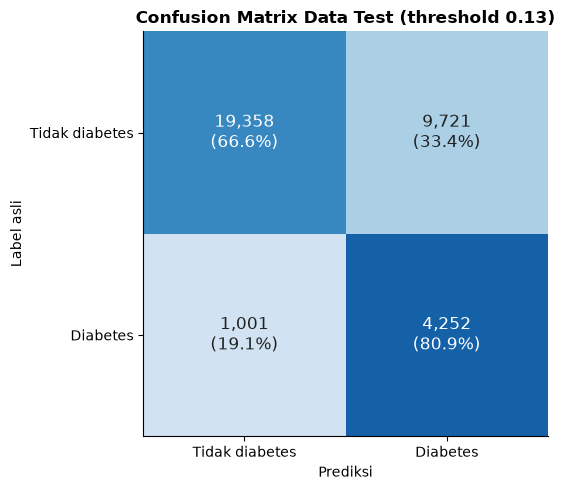

In [4]:
cm = np.array([[m_test["tn"], m_test["fp"]], [m_test["fn"], m_test["tp"]]])
cm_pct = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.1%})", ha="center", va="center", fontsize=12,
                color="white" if cm_pct[i, j] > 0.6 else "#222222")
lbl = [config.CLASS_LABELS[0], config.CLASS_LABELS[1]]
ax.set_xticks([0, 1], lbl)
ax.set_yticks([0, 1], lbl)
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli")
ax.grid(False)
ax.set_title(f"Confusion Matrix Data Test (threshold {THRESHOLD})", fontweight="bold")
fig.tight_layout()
viz.save_fig(fig, "eval_01_confusion_matrix_test")
plt.show()

**Interpretasi:** Di data test yang belum pernah dipakai sama sekali, model final menemukan **4.252 dari 5.253 penderita diabetes**, dengan recall **80,94%**. Ada 1.001 penderita yang terlewat. Sebagai harganya, 9.721 responden tanpa diabetes ikut ditandai berisiko, sehingga precision kelas diabetes 30,43% dan 40,70% responden ditandai berisiko. Specificity-nya 66,57%.

Ada dua cara membaca hasil ini:

- **Hasil "berisiko"** berarti sekitar 3 dari 10 orang yang ditandai memang diabetes. Ini wajar untuk alat skrining awal yang tujuannya mendorong orang memeriksakan diri.
- **Hasil "risiko rendah"** jauh lebih bisa dipegang. Precision kelas tidak diabetes mencapai 95,08%, artinya 95 dari 100 orang yang dinyatakan risiko rendah memang tidak diabetes.

Accuracy 68,77% lebih rendah dari model yang selalu menebak "tidak diabetes" (84,70%). Ini konsekuensi yang disengaja dari memprioritaskan recall, dan karena itu accuracy tidak dipakai sebagai metrik utama. PR-AUC 0,4318 sekitar 2,8 kali lipat dari nilai acak (0,153), dan ROC-AUC-nya 0,8128.

## **4. Interval Kepercayaan 95% (Bootstrap)**

Satu angka metrik dari satu data test belum menunjukkan seberapa pasti angka tersebut. Interval kepercayaan dihitung dengan *bootstrap*. Data test diambil ulang secara acak dengan pengembalian sebanyak 1.000 kali, metrik dihitung di setiap sampel, lalu persentil 2,5% dan 97,5% diambil sebagai batas interval. Threshold tetap 0,13 di semua sampel.

In [7]:
N_BOOT = 1000
n = len(y_test)
hasil_boot = []
for _ in range(N_BOOT):
    idx = rng.integers(0, n, n)
    yb, pb = y_test[idx], prob_test[idx]
    mb = ev.metrics_at_threshold(yb, pb, THRESHOLD)
    hasil_boot.append({"PR-AUC": average_precision_score(yb, pb), "ROC-AUC": roc_auc_score(yb, pb),
                       "Recall (sensitivitas)": mb["recall"], "Precision": mb["precision"],
                       "Specificity": mb["specificity"], "F1-score": mb["f1"], "F2-score": mb["f2"],
                       "Accuracy": mb["accuracy"]})
boot = pd.DataFrame(hasil_boot)
ci = pd.DataFrame({"nilai test": ringkas_test[boot.columns], "batas bawah 95%": boot.quantile(0.025),
                   "batas atas 95%": boot.quantile(0.975)})
ci["lebar interval"] = ci["batas atas 95%"] - ci["batas bawah 95%"]
ci.to_csv(config.RESULTS_DIR / "07_bootstrap_ci_test.csv")
display(ci.round(4))

,nilai test,batas bawah 95%,batas atas 95%,lebar interval
PR-AUC,0.4318,0.4175,0.4464,0.0288
ROC-AUC,0.8128,0.8072,0.8183,0.0111
Recall (sensitivitas),0.8094,0.7984,0.8195,0.0210
Precision,0.3043,0.2966,0.3124,0.0158
Specificity,0.6657,0.6605,0.6707,0.0102
F1-score,0.4423,0.4336,0.4513,0.0177
F2-score,0.6077,0.5987,0.6166,0.0179
Accuracy,0.6877,0.6828,0.6923,0.0096


**Interpretasi:** Interval kepercayaan 95% cukup sempit karena data test besar (34.332 responden). Recall berada di rentang 79,84% sampai 81,95%, precision 29,66% sampai 31,24%, F2 0,5987 sampai 0,6166, dan ROC-AUC 0,8072 sampai 0,8183. PR-AUC punya interval paling lebar (0,4175 sampai 0,4464), karena nilainya sangat dipengaruhi oleh sedikit responden dengan probabilitas tertinggi.

Recall di data validation (81,82%) masih berada di dalam interval test, jadi threshold yang dipilih di validation bekerja sesuai harapan di data baru. Sebaliknya, PR-AUC validation (0,4475) sedikit di atas batas atas interval test. Hal ini dibahas di Bagian 6.

Untuk laporan, angka utama sebaiknya ditulis beserta intervalnya, misalnya recall 80,94% (IK 95%: 79,84% sampai 81,95%).

## **5. Dengan dan Tanpa Fitur Unik di Data Test**

Model final memakai loss BCE, jadi perbedaan antara model dengan dan tanpa fitur unik pertama terletak pada threshold keputusan. Tiga skenario dibandingkan di data test:

| Skenario | Model | Threshold |
|---|---|---|
| A. Tanpa fitur unik | Model final | 0,5 (bawaan) |
| B. Dengan fitur unik 1 (model final) | Model final | 0,13 (F2 di validation) |
| C. Model pencarian bertahap (pembanding) | `mlp_tanpa_fitur_unik.keras` dari notebook 04 | F2 di validation milik model itu sendiri |

Skenario C bukan kandidat pengganti, karena model sudah dibekukan. Skenario ini hanya ditampilkan sebagai informasi untuk melihat apakah penggantian konfigurasi lewat Random Search di notebook 04b berdampak di data yang benar-benar baru. Threshold skenario C juga dipilih di data validation, bukan data test.

Fitur unik kedua (Integrated Gradients) tidak mengubah prediksi, sehingga dampaknya tidak bisa diukur dengan metrik klasifikasi. Buktinya ada di notebook 06 dan di Bagian 9.

,threshold,recall,precision,specificity,f1,f2,accuracy,persen_diprediksi_positif,pr_auc,roc_auc,tp,fp,fn
"A. Tanpa fitur unik (threshold 0,5)",0.500,0.1114,0.6277,0.9881,0.1892,0.1333,0.8539,0.0271,0.4318,0.8128,585,347,4668
B. Model final (threshold 0.13),0.130,0.8094,0.3043,0.6657,0.4423,0.6077,0.6877,0.4070,0.4318,0.8128,4252,9721,1001
C. Model bertahap notebook 04 (threshold 0.135),0.135,0.8281,0.2952,0.6428,0.4352,0.6084,0.6712,0.4292,0.4327,0.8137,4350,10386,903


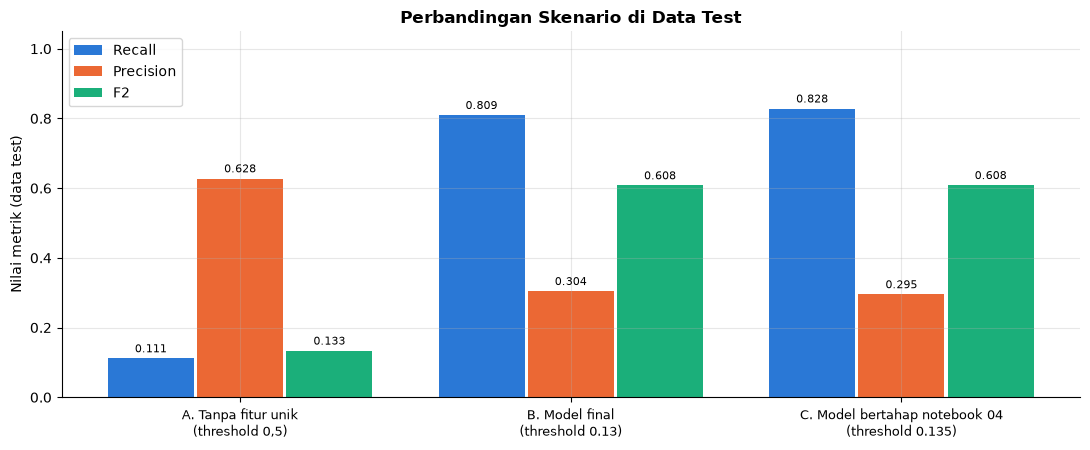

In [8]:
model_lama = keras.models.load_model(config.MODELS_DIR / "mlp_tanpa_fitur_unik.keras", compile=False)
prob_val_lama = inf.predict_proba(model_lama, data["X_val"])
t_lama = ev.pick_threshold(ev.threshold_curve(y_val, prob_val_lama), "f2")
prob_test_lama = inf.predict_proba(model_lama, data["X_test"])

skenario = {
    "A. Tanpa fitur unik (threshold 0,5)": (prob_test, 0.5),
    f"B. Model final (threshold {THRESHOLD})": (prob_test, THRESHOLD),
    f"C. Model bertahap notebook 04 (threshold {t_lama})": (prob_test_lama, t_lama),
}
banding = pd.DataFrame({nama: {**ev.metrics_at_threshold(y_test, p, t), **ev.ranking_metrics(y_test, p)}
                        for nama, (p, t) in skenario.items()}).T
kolom = ["threshold", "recall", "precision", "specificity", "f1", "f2", "accuracy", "persen_diprediksi_positif",
         "pr_auc", "roc_auc", "tp", "fp", "fn"]
banding = banding[kolom].astype({"tp": int, "fp": int, "fn": int})
banding.to_csv(config.RESULTS_DIR / "07_perbandingan_test.csv")
display(banding.round(4))

fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(banding))
for i, (kol, nama, warna) in enumerate([("recall", "Recall", WARNA["utama"]), ("precision", "Precision", WARNA["kedua"]),
                                        ("f2", "F2", WARNA["ketiga"])]):
    bar = ax.bar(x + (i - 1) * 0.27, banding[kol], width=0.26, color=warna, label=nama)
    for b, v in zip(bar, banding[kol]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, [s.replace(" (", "\n(") for s in banding.index], fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Nilai metrik (data test)")
ax.set_title("Perbandingan Skenario di Data Test", fontweight="bold")
ax.legend(loc="upper left")
fig.tight_layout()
viz.save_fig(fig, "eval_02_perbandingan_skenario_test")
plt.show()

In [9]:
# Paired bootstrap: selisih model bertahap (C) dikurangi model final (B) pada sampel test yang sama
rng_pair = np.random.default_rng(config.SEED + 1)
selisih = []
for _ in range(1000):
    idx = rng_pair.integers(0, n, n)
    yb = y_test[idx]
    mb = ev.metrics_at_threshold(yb, prob_test[idx], THRESHOLD)
    mc = ev.metrics_at_threshold(yb, prob_test_lama[idx], t_lama)
    selisih.append({"PR-AUC": average_precision_score(yb, prob_test_lama[idx]) - average_precision_score(yb, prob_test[idx]),
                    "ROC-AUC": roc_auc_score(yb, prob_test_lama[idx]) - roc_auc_score(yb, prob_test[idx]),
                    "F2-score": mc["f2"] - mb["f2"], "Recall": mc["recall"] - mb["recall"],
                    "Precision": mc["precision"] - mb["precision"]})
selisih = pd.DataFrame(selisih)
uji_pair = pd.DataFrame({"selisih rata-rata (C - B)": selisih.mean(), "batas bawah 95%": selisih.quantile(0.025),
                         "batas atas 95%": selisih.quantile(0.975)})
uji_pair["interval memuat 0"] = (uji_pair["batas bawah 95%"] <= 0) & (uji_pair["batas atas 95%"] >= 0)
uji_pair.to_csv(config.RESULTS_DIR / "07_paired_bootstrap_B_vs_C.csv")
display(uji_pair.round(4))

,selisih rata-rata (C - B),batas bawah 95%,batas atas 95%,interval memuat 0
PR-AUC,0.0008,-0.0029,0.0045,True
ROC-AUC,0.0009,-0.0004,0.0020,True
F2-score,0.0007,-0.0031,0.0043,True
Recall,0.0187,0.0134,0.0241,False
Precision,-0.0091,-0.0112,-0.0072,False


**Interpretasi:**

**Dampak fitur unik pertama di data test.** Perbandingan A dan B memakai model yang sama persis, yang berbeda hanya threshold-nya. Dengan threshold bawaan 0,5, model hanya menemukan **11,14%** penderita diabetes (585 orang) dan melewatkan 4.668 orang. Accuracy-nya 85,39%, hanya 0,69 poin di atas model yang selalu menebak "tidak diabetes". Dengan threshold 0,13 dari fitur unik pertama, recall naik menjadi **80,94%** dan F2 naik dari 0,1333 menjadi 0,6077, atau sekitar 4,6 kali lipat. Jumlah penderita yang terlewat turun dari 4.668 menjadi 1.001. Hasil ini sama dengan temuan di data validation, jadi dampak fitur unik pertama terbukti di data yang benar-benar baru.

**Model final dibandingkan model pencarian bertahap.** Model bertahap dari notebook 04 (skenario C) mendapat PR-AUC 0,4327, ROC-AUC 0,8137, dan F2 0,6084. Angka ini sedikit di atas model final (0,4318, 0,8128, dan 0,6077). Uji *paired bootstrap* menunjukkan selisih ketiga metrik ini **tidak bermakna**, karena interval 95%-nya memuat nol. Contohnya, selisih F2 adalah +0,0007 dengan interval -0,0031 sampai 0,0043. Yang berbeda bermakna hanya pertukaran recall dan precision. Model bertahap punya recall 1,87 poin lebih tinggi tetapi precision 0,91 poin lebih rendah, karena ia menandai lebih banyak responden (42,92% berbanding 40,70%).

Artinya, keunggulan kecil konfigurasi Random Search di data validation (+0,0011 PR-AUC) **tidak muncul di data test**. Ini sesuai dengan catatan di notebook 04b bahwa kandidat yang dipilih dari banyak percobaan di data validation yang sama cenderung terlihat sedikit lebih baik daripada kenyataannya. Model final **tidak diganti** berdasarkan hasil ini, karena memilih model berdasarkan data test justru membuat evaluasi akhir tidak lagi objektif. Kesimpulan yang jujur untuk laporan: kedua konfigurasi setara, dan pilihan konfigurasi tidak memengaruhi performa secara berarti.

## **6. Generalisasi: Train, Validation, dan Test**

Metrik model final dibandingkan di ketiga bagian data. Kalau performa di test jauh lebih rendah daripada validation, berarti ada overfitting terhadap data validation selama pemilihan hyperparameter dan threshold. Kalau performa di train jauh lebih tinggi daripada keduanya, berarti model menghafal data train.

In [10]:
prob_train = inf.predict_proba(model, data["X_train"])
y_train = data["y_train"].astype(int)
gen = pd.DataFrame({
    nama: {**ev.ranking_metrics(y, p), **{k: ev.metrics_at_threshold(y, p, THRESHOLD)[k]
                                          for k in ["recall", "precision", "f2", "persen_diprediksi_positif"]}}
    for nama, (y, p) in {"train": (y_train, prob_train), "validation": (y_val, prob_val), "test": (y_test, prob_test)}.items()
}).T
gen["prevalensi"] = [y_train.mean(), y_val.mean(), y_test.mean()]
display(gen.round(4))
print(f"Selisih PR-AUC validation - test : {gen.loc['validation', 'pr_auc'] - gen.loc['test', 'pr_auc']:+.4f}")
print(f"Selisih F2 validation - test     : {gen.loc['validation', 'f2'] - gen.loc['test', 'f2']:+.4f}")
print(f"Selisih PR-AUC train - test      : {gen.loc['train', 'pr_auc'] - gen.loc['test', 'pr_auc']:+.4f}")

,pr_auc,roc_auc,recall,precision,f2,persen_diprediksi_positif,prevalensi
train,0.4455,0.8216,0.8178,0.3077,0.6141,0.4067,0.153
validation,0.4475,0.8184,0.8182,0.3065,0.6134,0.4083,0.153
test,0.4318,0.8128,0.8094,0.3043,0.6077,0.4070,0.153


Selisih PR-AUC validation - test : +0.0157
Selisih F2 validation - test     : +0.0057
Selisih PR-AUC train - test      : +0.0137


**Interpretasi:** PR-AUC train (0,4455) dan validation (0,4475) hampir sama, jadi model **tidak menghafal data train**. Performa di test sedikit lebih rendah, yaitu PR-AUC 0,4318 (turun 0,0157 dari validation) dan F2 0,6077 (turun 0,0057).

Penurunan F2 ini hampir sama dengan perkiraan dari uji stabilitas threshold di notebook 05 (0,0047). Recall dan persentase responden yang ditandai berisiko juga sangat stabil di ketiga bagian data, yaitu 81,78%, 81,82%, dan 80,94% untuk recall, serta 40,67%, 40,83%, dan 40,70% untuk persentase berisiko. Jadi cara kerja threshold di data baru sesuai dengan yang diharapkan.

Penurunan PR-AUC kemungkinan berasal dari dua hal. Pertama, variasi acak antar-sampel, karena interval PR-AUC di test cukup lebar (lebar 0,029). Kedua, sedikit optimisme di data validation, karena data validation dipakai untuk memilih dari lebih dari 100 model di notebook 03 sampai 05. Inilah alasan angka performa akhir harus diambil dari data test, bukan dari validation.